# Exp 16: farmer welfare vs. ε_h in the stylized model (exp_10 instances)

exp_10's 44 two-type instances (`experiments/exp_10/small_window_instances.csv`), with all parameters fixed except the high-type ambiguity level ε_h, which is swept on a fine grid. For each ε_h we record the **minimum and maximum farmer welfare over all platform-optimal solutions** (§3.2.3).

**Model.** The stylized (S-PFP) of §3.2 with linear collection costs, i.e. exactly exp_11's linear-cost setting. Several instances violate parts of Assumption 1 (the CSV's `A1_violations`: (b), (d), (g), |F|/K integral), so Proposition 4 / Lemma 1(vi) are not used. Instead (S-PFP) is solved numerically, with no branch-and-bound:

- For each matched composition (x_h high, x_l low types, (x_h + x_l)K ≥ |F|), solve the LP
  max Σ_f v_f − Σ_{t∈T}(σ_t + π_t) s.t. π_t ≥ π̃_t(v), π_t ≥ 0 for t ∈ T, π̃_t(v) ≤ 0 for t ∉ T, v_f ≤ p − c_f,
  where π̃_t(v) is the deviation LP (EC29), written through its dual. Intermediaries of a type are interchangeable, so the composition determines the value.
- Π* is the best composition's value. A composition is optimal if it is within `TOL` = 1.0 of Π* (the solver's `PRIMARY_OBJECTIVE_TOL`).
- For each optimal composition, re-solve with platform profit ≥ (its value − `TOL`) and minimize / maximize Σ_f v_f. Farmer welfare is W^F = Σ_f (p − c_f − v_f).
- **Over all optimal solutions** (the paper's definition): W^F_min / W^F_max are the min / max across optimal compositions. **Within the chosen matching** (what the solver reports) is the per-composition range.

Welfare is reported for the **zero** arm (c_f = 0, the CSV's own c_f). In the **star** arm, the bound v_f ≤ p − c_f never binds (checked below), so its farmer welfare is the zero arm's minus the constant Σ_f c_f. Profit is identical in both arms.

In [1]:
import glob
import gzip
import json
import time
from pathlib import Path

import gurobipy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from stable_platform_matchings.domain.instance import Instance

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
INSTANCES_CSV = ROOT / "experiments/exp_10/small_window_instances.csv"
EXP_11 = ROOT / "results/exp_11"
OUT = ROOT / "results/exp_16"
OUT.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "figures/exp_16"
FIG.mkdir(parents=True, exist_ok=True)

SIGMA_ELL = float(Instance.TRUCK_FIXED_COST)
PRICE = float(Instance.FRUIT_PRICE_PER_TON)  # farmer_quantity = 1 ton in every row
TOL = 1.0
GRID_STEP = 0.01
RECOMPUTE = False

windows = pd.read_csv(INSTANCES_CSV).set_index("instance").sort_index()
assert (windows["farmer_quantity"] == 1).all() and (windows["c_f"] == 0).all()
assert (windows["n_farmers"] == windows["T_h"] * windows["n_h"] + windows["T_l"] * windows["n_l"]).all()
# derived Prop 3 quantities, as in exp_10.load_windows
windows["a"] = windows["n_l"] + windows["eps_l"]
windows["L"] = windows["K"] - windows["n_h"]
windows["M"] = windows["T_l"] * windows["n_l"] / windows["T_h"]
b = windows["M"] + windows["a"]
disc = b**2 - 4 * windows["M"] * windows["rho"] * windows["a"]
windows["eps_h_minus"] = np.where(disc >= 0, (b - np.sqrt(disc.clip(lower=0))) / 2, np.nan)
windows["eps_h_plus"] = np.where(disc >= 0, (b + np.sqrt(disc.clip(lower=0))) / 2, np.nan)
env = gp.Env(params={"OutputFlag": 0})
len(windows)

44

In [2]:
SIGMA_ELL

800000.0

In [7]:
windows["sigma_h / e_l"] = windows["sigma_h"]/ (windows["n_l"] + windows["eps_l"])

In [8]:
windows["sigma_h / e_l"] 

instance
1     0.400000
2     0.275000
3     0.433333
4     0.220000
5     0.650000
6     0.650000
7     0.700000
8     0.400000
9     0.275000
10    0.800000
11    0.433333
12    0.400000
13    0.275000
14    0.700000
15    0.433333
16    0.433333
17    0.275000
18    0.600000
19    0.600000
20    0.600000
21    0.600000
22    0.650000
23    0.650000
24    0.650000
25    0.650000
26    0.400000
27    0.400000
28    0.400000
29    0.600000
30    0.650000
31    0.366667
32    0.600000
33    0.650000
34    0.366667
35    0.550000
36    0.650000
37    0.700000
38    0.650000
39    0.700000
40    0.550000
41    0.550000
42    0.550000
43    0.550000
44    0.550000
Name: sigma_h / e_l, dtype: float64

In [4]:
windows.columns

Index(['K', 'n_h', 'n_l', 'eps_l', 'T_h', 'T_l', 'n_intermediaries',
       'n_farmers', 'farmer_quantity', 'min_trucks', 'sigma_l', 'sigma_h',
       'rho', 'p', 'c_f', 'eps_h_sweep', 'regime_by_eps_h', 'ineff_eps_h_min',
       'ineff_eps_h_max', 'matched_high_in_window', 'matched_low_in_window',
       'min_abs_profit_margin', 'A1_a', 'A1_b', 'A1_c', 'A1_d', 'A1_e', 'A1_g',
       'A1_F_div_K', 'A1_violations', 'a', 'L', 'M', 'eps_h_minus',
       'eps_h_plus'],
      dtype='str')

## The LP

In [2]:
class CompositionLP:
    # (S-PFP) with the matched set fixed to the first x_h high and first x_l low types.
    # Variables: margins v_f; per intermediary t its profit pi_t and the dual (eta_t, lam_t, w_tf)
    # of the deviation LP (EC29): pi~_t(v) = -sigma_t + min eps_t*eta_t + K*lam_t + sum_f w_tf
    # s.t. w_tf + lam_t + eta_t*1[f not in H_t] >= v_f.

    def __init__(self, row, x_h, x_l):
        T_h, T_l = int(row["T_h"]), int(row["T_l"])
        n_h, n_l, K = int(row["n_h"]), int(row["n_l"]), float(row["K"])
        types = ["h"] * T_h + ["l"] * T_l
        owner = [t for t, ty in enumerate(types) for _ in range(n_h if ty == "h" else n_l)]
        matched = [(t < x_h) if ty == "h" else (t - T_h < x_l) for t, ty in enumerate(types)]
        sigma = [float(row["rho"]) * SIGMA_ELL if ty == "h" else SIGMA_ELL for ty in types]
        n_t, n_f = len(types), len(owner)

        m = gp.Model(env=env)
        v = m.addVars(n_f, lb=-gp.GRB.INFINITY, ub=PRICE)  # v_f <= p - c_f with c_f = 0
        pi = m.addVars(n_t, lb=0.0)
        eta = m.addVars(n_t, lb=0.0)
        lam = m.addVars(n_t, lb=0.0)
        w = m.addVars(n_t, n_f, lb=0.0)
        stab = {}
        for t in range(n_t):
            if not matched[t]:
                pi[t].UB = 0.0  # unmatched: no pay, so pi~_t(v) <= 0
            eps_t = float(row["eps_l"]) if types[t] == "l" else 0.0  # eps_h set per solve
            stab[t] = m.addConstr(pi[t] - eps_t * eta[t] - K * lam[t] - w.sum(t, "*") >= -sigma[t])
            for f in range(n_f):
                m.addConstr(w[t, f] + lam[t] + (eta[t] if owner[f] != t else 0) >= v[f])
        self.m, self.v, self.eta, self.stab = m, v, eta, stab
        self.high = [t for t in range(n_t) if types[t] == "h"]
        self.profit = v.sum() - gp.quicksum(pi[t] + sigma[t] for t in range(n_t) if matched[t])
        self.sum_v = v.sum()

    def set_eps_h(self, eps_h):
        for t in self.high:
            self.m.chgCoeff(self.stab[t], self.eta[t], -eps_h)

    def max_profit(self):
        self.m.setObjective(self.profit, gp.GRB.MAXIMIZE)
        self.m.optimize()
        return self.m.ObjVal if self.m.Status == gp.GRB.OPTIMAL else None

    def sum_v_range(self, profit_floor):
        # min / max of sum_f v_f over solutions with platform profit >= profit_floor
        c = self.m.addConstr(self.profit >= profit_floor)
        out = []
        for sense in (gp.GRB.MINIMIZE, gp.GRB.MAXIMIZE):
            self.m.setObjective(self.sum_v, sense)
            self.m.optimize()
            out.append(self.m.ObjVal)
        self.m.remove(c)
        return out


def build_lps(row):
    T_h, T_l, K, F = int(row["T_h"]), int(row["T_l"]), float(row["K"]), int(row["n_farmers"])
    return {
        (x_h, x_l): CompositionLP(row, x_h, x_l)
        for x_h in range(T_h + 1) for x_l in range(T_l + 1) if (x_h + x_l) * K >= F
    }


def solve_point(lps, eps_h, n_farmers):
    # profit of every composition, and the farmer-welfare range (zero arm) of every optimal one
    for lp in lps.values():
        lp.set_eps_h(eps_h)
    profits = {c: lp.max_profit() for c, lp in lps.items()}
    profits = {c: p for c, p in profits.items() if p is not None}
    best = max(profits.values())
    comps = {}
    for c, p in profits.items():
        if p >= best - TOL:
            sv_min, sv_max = lps[c].sum_v_range(p - TOL)
            comps[c] = (p, n_farmers * PRICE - sv_max, n_farmers * PRICE - sv_min)  # (profit, fw_min, fw_max)
    return best, comps

## Check against exp_11

At every ε_h exp_11 solved, the matching the solver chose must be LP-optimal. The LP's optimal profit, and the farmer-welfare range within that matching, must equal the solver's: `max_intermediary_welfare_result` gives the minimum, `max_farmer_welfare_result` the maximum. For the star arm, farmer welfare is shifted by −Σ_f c_f.

In [3]:
rows = []
start = time.time()
for arm in ["zero", "star"]:
    for path in sorted(glob.glob(str(EXP_11 / arm / "job_*" / "*.json.gz"))):
        with gzip.open(path, "rt") as f:
            job = json.load(f)
        row = windows.loc[job["instance_id"]]
        high = set(job["high_ids"])
        sum_c = sum(job["collection_costs"]["c_f"].values())
        max_c = job["collection_costs"]["c_f_max"]
        lps = build_lps(row)
        for run in job["runs"]:
            best, comps = solve_point(lps, run["eps_h"], int(row["n_farmers"]))
            psr = run["summary"]["platform_solve_result"]
            sel = set(psr["primary_result"]["selected_intermediaries"])
            c = (len(sel & high), len(sel - high))
            rec = dict(arm=arm, instance=job["instance_id"], eps_h=run["eps_h"], chosen_optimal=c in comps,
                       profit_err=abs(best - psr["primary_result"]["platform_profit"]),
                       # star arm: v_f <= p - c_f must not bind, i.e. the LP's margins stay below p - max c_f
                       margin_slack=PRICE - max_c - max(lps[c].v[f].X for f in lps[c].v) if c in comps else np.nan)
            if c in comps:
                _, lo, hi = comps[c]
                rec["fw_min_err"] = abs(lo - sum_c - psr["max_intermediary_welfare_result"]["farmer_welfare"])
                rec["fw_max_err"] = abs(hi - sum_c - psr["max_farmer_welfare_result"]["farmer_welfare"])
            rows.append(rec)
check = pd.DataFrame(rows)
print(f"{len(check)} exp_11 points in {time.time() - start:.0f}s")
check.groupby("arm").agg(points=("eps_h", "size"), chosen_optimal=("chosen_optimal", "mean"),
                         max_profit_err=("profit_err", "max"), max_fw_min_err=("fw_min_err", "max"),
                         max_fw_max_err=("fw_max_err", "max"), min_margin_slack=("margin_slack", "min"))

3094 exp_11 points in 39s


,points,chosen_optimal,max_profit_err,max_fw_min_err,max_fw_max_err,min_margin_slack
arm,,,,,,
star,1552,1.0,1.243316e-07,0.742014,0.274446,1.233674e+06
zero,1542,1.0,1.187436e-07,2.159410,0.000005,2.113000e+06


Errors are in IDR, against farmer welfare of about 10⁷ to 10⁸. Differences up to a few IDR come from the 1.0 optimality tolerance, applied slightly differently in the two re-optimizations. The positive margin slack confirms that v_f ≤ p − c_f never binds in the star arm, so its welfare is the zero arm's shifted by Σ_f c_f.

## Full sweep

ε_h ∈ [0, L + 1] in steps of 0.01 (exp_10's sweep range, with `L` = K − n_h the saturation point), for all 44 instances. Results are cached to `results/exp_16/sweep.csv.gz`; set `RECOMPUTE = True` to rerun.

In [4]:
SWEEP_PATH = OUT / "sweep.csv.gz"
if SWEEP_PATH.exists() and not RECOMPUTE:
    sweep = pd.read_csv(SWEEP_PATH)
else:
    rows = []
    start = time.time()
    for instance_id, row in windows.iterrows():
        lps = build_lps(row)
        T_h, F = int(row["T_h"]), int(row["n_farmers"])
        grid = np.round(np.arange(0, row["L"] + 1 + GRID_STEP / 2, GRID_STEP), 6)
        for eps_h in grid:
            best, comps = solve_point(lps, float(eps_h), F)
            x_hs = sorted({c[0] for c in comps})
            chosen = max(comps, key=lambda c: comps[c][0])  # best composition (a solver-style single matching)
            rows.append(dict(
                instance=instance_id, eps_h=float(eps_h), profit=best,
                optimal_compositions=";".join(f"{a}-{b}" for a, b in sorted(comps)),
                n_optimal=len(comps), high_matched_min=x_hs[0], high_matched_max=x_hs[-1], T_h=T_h,
                fw_min=min(v[1] for v in comps.values()), fw_max=max(v[2] for v in comps.values()),
                fw_min_chosen=comps[chosen][1], fw_max_chosen=comps[chosen][2],
                fruit_value=F * PRICE,
            ))
    sweep = pd.DataFrame(rows)
    sweep.to_csv(SWEEP_PATH, index=False)
    print(f"{len(sweep)} points in {time.time() - start:.0f}s")

def regime(r):
    if r.n_optimal > 1 and r.high_matched_min != r.high_matched_max:
        return "tie"
    if r.high_matched_min == 0:
        return "E"  # efficient: no high type matched
    return "I" if r.high_matched_min == r.T_h else "P"  # all / some high types matched

sweep["regime"] = [regime(r) for r in sweep.itertuples()]
sweep = sweep.merge(windows[["K", "n_h", "L", "eps_h_minus", "eps_h_plus"]], left_on="instance", right_index=True)
sweep["saturated"] = sweep["n_h"] + sweep["eps_h"] > sweep["K"]
for col in ["fw_min", "fw_max", "fw_min_chosen", "fw_max_chosen"]:
    sweep[col + "_pct"] = 100 * sweep[col] / sweep["fruit_value"]
sweep["fw_width"] = sweep["fw_max"] - sweep["fw_min"]
sweep.groupby("regime").agg(points=("eps_h", "size"), instances=("instance", "nunique"))

,points,instances
regime,,
E,19042,44
I,11883,44
tie,219,21


`E`: only low types matched (efficient). `I`: all high types matched. `P`: some but not all, as the unique optimum. `tie`: optimal matchings with different numbers of high types (switch points, at the grid's resolution).

## Does Prop 4 survive the relaxed assumptions?

Proposition 4(ii) says that within each matching regime and capacity regime (n_h + ε_h ≤ K or > K):

- both W^F_min and W^F_max are nondecreasing in ε_h;
- with all high types matched, W^F_min is constant in ε_h;
- with only low types matched, the range collapses, W^F_min = W^F_max.

The check runs over maximal runs of consecutive grid points with the same regime and capacity side, ties excluded. The slack is 200 IDR, about 10⁻⁵ of fruit value. The 1.0-IDR optimality tolerance lets the welfare re-optimizations drift by up to about 100 IDR, which is visible once capacity binds with high types matched, where the range should be a single point.

In [5]:
SLACK = 200.0
checks = []
for instance_id, g in sweep[sweep["regime"] != "tie"].groupby("instance"):
    g = g.sort_values("eps_h")
    run_id = ((g["regime"] != g["regime"].shift()) | (g["saturated"] != g["saturated"].shift())).cumsum()
    for _, seg in g.groupby(run_id):
        d_min, d_max = seg["fw_min"].diff().dropna(), seg["fw_max"].diff().dropna()
        reg = seg["regime"].iloc[0]
        checks.append(dict(
            instance=instance_id, regime=reg, saturated=seg["saturated"].iloc[0],
            eps_from=seg["eps_h"].min(), eps_to=seg["eps_h"].max(), points=len(seg),
            fw_min_decreases=int((d_min < -SLACK).sum()), fw_max_decreases=int((d_max < -SLACK).sum()),
            fw_min_not_constant=int(reg == "I" and (seg["fw_min"].max() - seg["fw_min"].min()) > SLACK),
            range_not_collapsed=int(reg == "E" and seg["fw_width"].max() > SLACK),
            max_width_pct=100 * (seg["fw_width"] / seg["fruit_value"]).max(),
        ))
checks = pd.DataFrame(checks)
viol = checks[(checks[["fw_min_decreases", "fw_max_decreases", "fw_min_not_constant", "range_not_collapsed"]] > 0).any(axis=1)]
print(f"{len(checks)} regime segments across {checks['instance'].nunique()} instances; {len(viol)} with a violation")
checks.groupby(["regime", "saturated"])[["points", "fw_min_decreases", "fw_max_decreases", "fw_min_not_constant", "range_not_collapsed", "max_width_pct"]].agg(
    {"points": "sum", "fw_min_decreases": "sum", "fw_max_decreases": "sum", "fw_min_not_constant": "sum", "range_not_collapsed": "sum", "max_width_pct": "max"})

208 regime segments across 44 instances; 1 with a violation


points  fw_min_decreases  fw_max_decreases  \
regime saturated                                               
E      False       17653                 0                 0   
       True         1389                 0                 0   
I      False        9091                 0                 0   
       True         2792                 0                 0   

                  fw_min_not_constant  range_not_collapsed  max_width_pct  
regime saturated                                                           
E      False                        0                    1       0.353718  
       True                         0                    0       0.000005  
I      False                        0                    0      11.105054  
       True                         0                    0       0.000241

In [6]:
viol

,instance,regime,saturated,eps_from,eps_to,points,fw_min_decreases,fw_max_decreases,fw_min_not_constant,range_not_collapsed,max_width_pct
75,17,E,False,0.0,5.1,511,0,0,0,1,0.353718


**The one real departure: #17 at ε_h < 0.4.** Here the efficient regime's range does not collapse (up to 320k IDR, 0.35% of fruit value, at ε_h = 0). The cause is Assumption 1(d), not the flagged (b): σ_h / min(n_h + ε_h, K) = 1.1 σ_ℓ / (4 + ε_h) exceeds e_ℓ = σ_ℓ/4 until ε_h = 0.4. In that range the unmatched high types' farmers carry the top margin v̄ = σ_h/n_h > e_ℓ (the case Lemma 1's proof rules out). A matched low type's farmers can then be given margins anywhere in [(σ_ℓ − ε_ℓ v̄)/n_ℓ, v̄]. Every unit of margin moved there comes back to the platform as low-type intermediary profit, so its profit is unchanged and the farmer–intermediary split is free. The width is 4 matched lows × 3 farmers × (0.275 − 0.2417)σ_ℓ = 320k, matching the LP. Unlike Prop 4(i) predicts, matched low types can therefore earn positive profit in some optimal solutions.

In [7]:
g17 = sweep[(sweep["instance"] == 17) & (sweep["eps_h"] <= 0.6)].sort_values("eps_h")
w17 = windows.loc[17]
pd.DataFrame({
    "eps_h": g17["eps_h"],
    "A1(d) holds": float(w17.rho) / np.minimum(w17.n_h + g17["eps_h"], w17.K) < 1 / (w17.n_l + w17.eps_l),
    "fw_width_IDR": g17["fw_width"].round(0),
}).iloc[::5]

,eps_h,A1(d) holds,fw_width_IDR
13316,0.00,False,320002.0
13321,0.05,False,276545.0
13326,0.10,False,234148.0
13331,0.15,False,192773.0
13336,0.20,False,152383.0
13341,0.25,False,112943.0
13346,0.30,False,74420.0
13351,0.35,False,36783.0
13356,0.40,False,2.0
13361,0.45,True,2.0


## Overview: all 44 instances

Each panel shows one instance. The band is farmer welfare across all optimal solutions, as a share of fruit value: the top edge is W^F_max, the bottom W^F_min. The gray shading marks where every optimal matching includes all high types, the dashed lines mark the predicted window (ε_h⁻, ε_h⁺) from (EC3), and the solid line marks `L`. Each panel has its own y-scale. Unshaded stretches with a wide band past `L` (#8, #19, #39) are persistent ties: there, an efficient matching and one with a high type are equally profitable over a whole interval, and the band covers both.

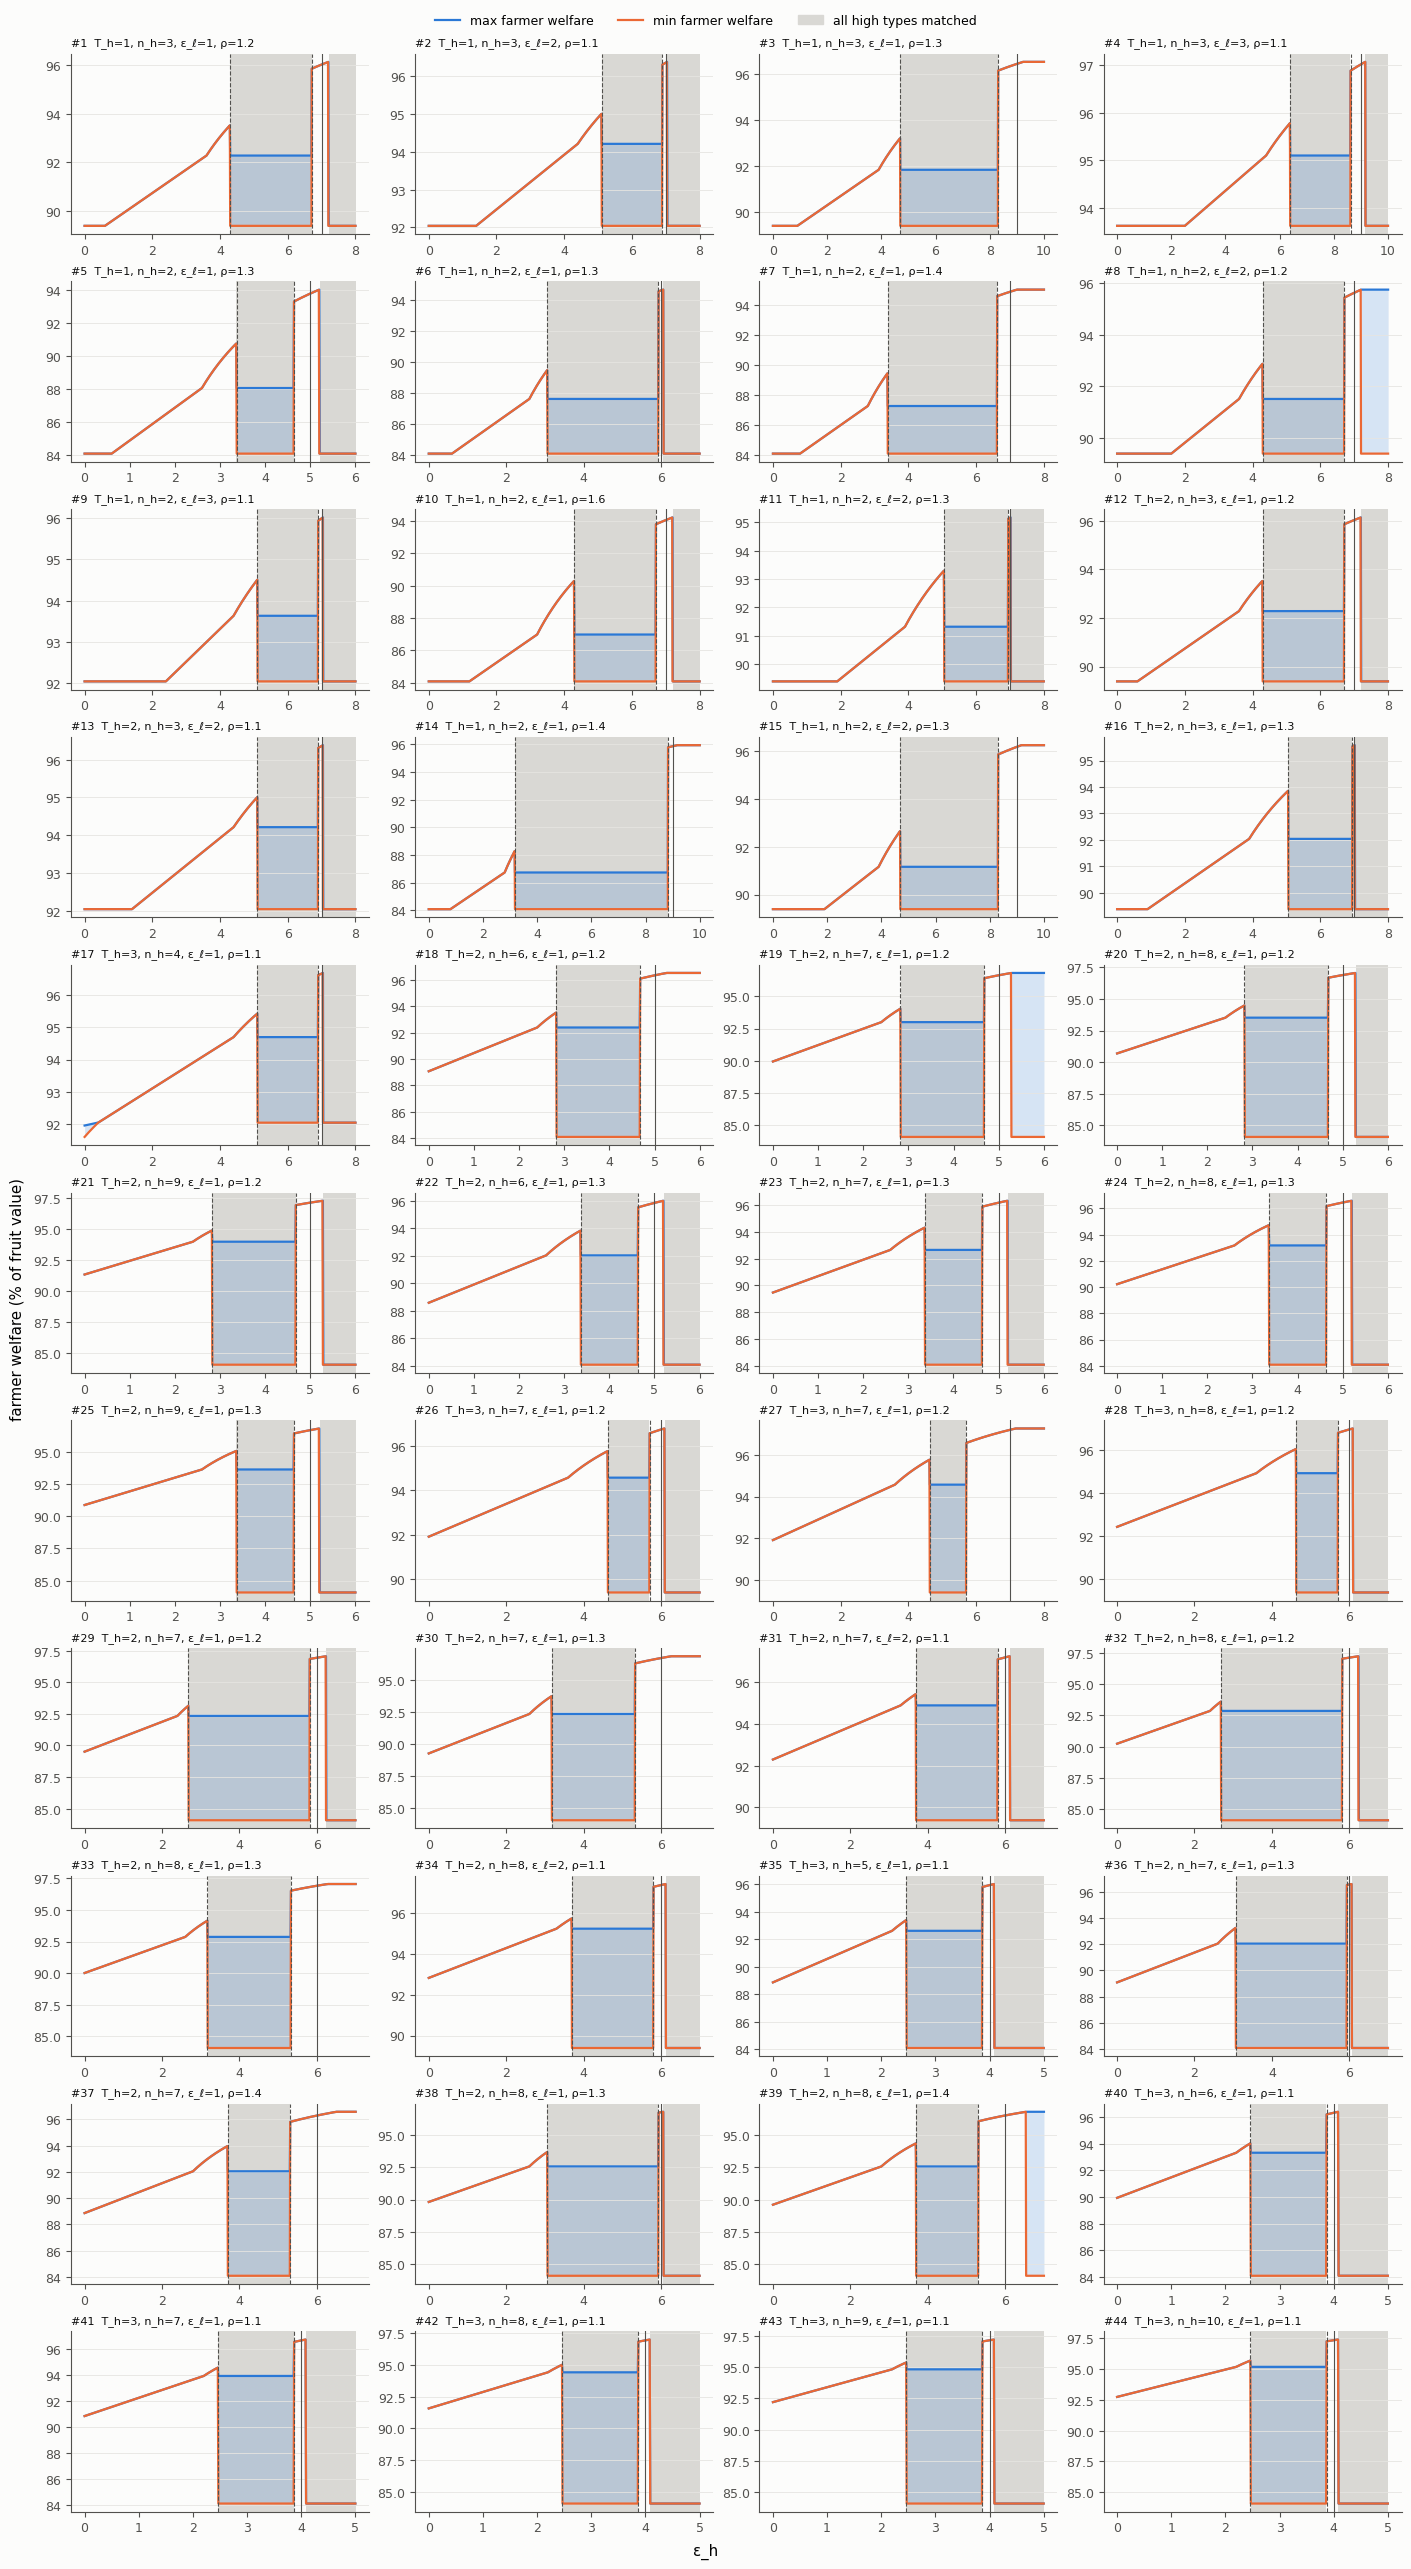

In [8]:
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
SURFACE = "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})


def shade_regime(ax, g, regime="I"):
    on = (g["regime"] == regime).to_numpy()
    eps = g["eps_h"].to_numpy()
    starts = np.flatnonzero(on & ~np.r_[False, on[:-1]])
    ends = np.flatnonzero(on & ~np.r_[on[1:], False])
    for s, e in zip(starts, ends):
        ax.axvspan(eps[s] - GRID_STEP / 2, eps[e] + GRID_STEP / 2, color="#d9d8d4", lw=0, zorder=0)


def draw(ax, instance_id, labels=False):
    g = sweep[sweep["instance"] == instance_id].sort_values("eps_h")
    w = windows.loc[instance_id]
    shade_regime(ax, g)
    ax.fill_between(g["eps_h"], g["fw_min_pct"], g["fw_max_pct"], color=BLUE, alpha=0.18, lw=0)
    ax.plot(g["eps_h"], g["fw_max_pct"], color=BLUE, lw=1.6, label="max farmer welfare")
    ax.plot(g["eps_h"], g["fw_min_pct"], color=ORANGE, lw=1.6, label="min farmer welfare")
    for x in (w["eps_h_minus"], w["eps_h_plus"]):
        if pd.notna(x):
            ax.axvline(x, color=MUTED, lw=0.8, ls="--")
    ax.axvline(w["L"], color=MUTED, lw=0.8)
    ax.set_title(f"#{instance_id}  T_h={int(w.T_h)}, n_h={int(w.n_h)}, ε_ℓ={int(w.eps_l)}, ρ={w.rho}", fontsize=8, color=INK, loc="left")
    ax.grid(axis="y", color="#e6e5e1", lw=0.6)
    if labels:
        ax.set_ylabel("farmer welfare (% of fruit value)")


ids = list(windows.index)
ncol = 4
fig, axes = plt.subplots(int(np.ceil(len(ids) / ncol)), ncol, figsize=(14, 2.3 * np.ceil(len(ids) / ncol)), constrained_layout=True)
for ax, instance_id in zip(axes.flat, ids):
    draw(ax, instance_id)
for ax in axes.flat[len(ids):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
handles.append(plt.Rectangle((0, 0), 1, 1, color="#d9d8d4"))
labels.append("all high types matched")
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.012))
fig.supxlabel("ε_h")
fig.supylabel("farmer welfare (% of fruit value)")
fig.savefig(FIG / "fw_band_all_instances.png", dpi=150, bbox_inches="tight")
plt.show()

## A closer look

The instances with the widest welfare range, and instance #1. The top row shows farmer welfare, the bottom row platform profit (in units of σ_ℓ), on separate axes.

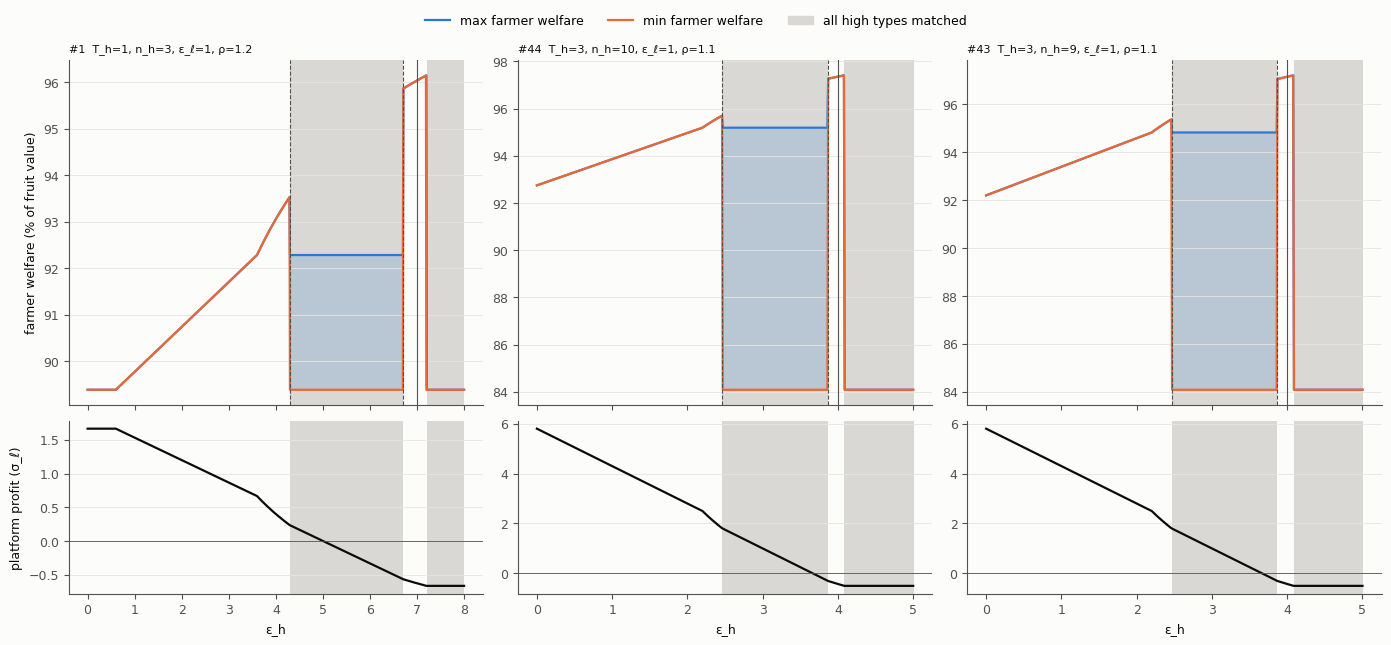

In [9]:
widest = sweep.groupby("instance")["fw_width"].max().sort_values(ascending=False)
focus = [1] + [i for i in widest.index if i != 1][:2]
fig, axes = plt.subplots(2, len(focus), figsize=(4.6 * len(focus), 6), sharex="col", constrained_layout=True,
                         gridspec_kw={"height_ratios": [2, 1]})
for j, instance_id in enumerate(focus):
    draw(axes[0, j], instance_id, labels=(j == 0))
    g = sweep[sweep["instance"] == instance_id].sort_values("eps_h")
    shade_regime(axes[1, j], g)
    axes[1, j].plot(g["eps_h"], g["profit"] / SIGMA_ELL, color=INK, lw=1.6)
    axes[1, j].axhline(0, color=MUTED, lw=0.6)
    axes[1, j].set_xlabel("ε_h")
    axes[1, j].grid(axis="y", color="#e6e5e1", lw=0.6)
axes[1, 0].set_ylabel("platform profit (σ_ℓ)")
handles, labels = axes[0, 0].get_legend_handles_labels()
handles.append(plt.Rectangle((0, 0), 1, 1, color="#d9d8d4"))
labels.append("all high types matched")
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.06))
fig.savefig(FIG / "fw_band_focus.png", dpi=150, bbox_inches="tight")
plt.show()

## Within the solver's matching vs. over all optimal matchings

At ties between matchings (switch points), the range over all optimal solutions is the union of the per-matching ranges, and can be wider than what a single solve reports.

In [10]:
gap = sweep.assign(extra_low=sweep["fw_min_chosen"] - sweep["fw_min"], extra_high=sweep["fw_max"] - sweep["fw_max_chosen"])
wider = gap[(gap["extra_low"] > SLACK) | (gap["extra_high"] > SLACK)]
print(f"{len(wider)} of {len(sweep)} grid points have a wider range across matchings than within the best one")
wider[["instance", "eps_h", "regime", "optimal_compositions", "fw_min_pct", "fw_min_chosen_pct", "fw_max_chosen_pct", "fw_max_pct"]].head(20)

219 of 31144 grid points have a wider range across matchings than within the best one


,instance,eps_h,regime,optimal_compositions,fw_min_pct,fw_min_chosen_pct,fw_max_chosen_pct,fw_max_pct
720,1,7.20,tie,0-2;1-1,89.388511,96.141277,96.141281,96.141281
1505,2,7.04,tie,0-2;1-1,92.041385,96.382448,96.382451,96.382451
4124,5,5.20,tie,0-2;1-1,84.082770,84.082770,84.082819,94.031044
6427,8,7.20,tie,0-2;1-1,89.388513,95.755405,95.755409,95.755409
6428,8,7.21,tie,0-2;1-1,89.388513,95.755405,95.755409,95.755409
6429,8,7.22,tie,0-2;1-1,89.388513,95.755405,95.755409,95.755409
6430,8,7.23,tie,0-2;1-1,89.388513,95.755405,95.755409,95.755409
6431,8,7.24,tie,0-2;1-1,89.388513,95.755405,95.755409,95.755409
6432,8,7.25,tie,0-2;1-1,89.388513,95.755405,95.755409,95.755409
6433,8,7.26,tie,0-2;1-1,89.388513,95.755405,95.755409,95.755409


## Per-instance summary

In [11]:
def at(g, eps):
    return g.iloc[(g["eps_h"] - eps).abs().argmin()]

summary = []
for instance_id, g in sweep.groupby("instance"):
    g = g.sort_values("eps_h")
    inef = g[g["regime"] == "I"]
    first, last = g.iloc[0], g.iloc[-1]
    summary.append(dict(
        instance=instance_id, A1_violations=windows.loc[instance_id, "A1_violations"],
        regimes="".join(k for k, _ in __import__("itertools").groupby(g["regime"])),
        I_from=inef["eps_h"].min() if len(inef) else np.nan, I_to=inef["eps_h"].max() if len(inef) else np.nan,
        eps_h_minus=windows.loc[instance_id, "eps_h_minus"], eps_h_plus=windows.loc[instance_id, "eps_h_plus"],
        L=windows.loc[instance_id, "L"],
        fw_min_at_0=first["fw_min_pct"], fw_max_at_0=first["fw_max_pct"],
        fw_min_at_end=last["fw_min_pct"], fw_max_at_end=last["fw_max_pct"],
        max_width_pct=100 * (g["fw_width"] / g["fruit_value"]).max(),
    ))
summary = pd.DataFrame(summary).set_index("instance")
summary.to_csv(OUT / "summary.csv")
summary.round(3)

,A1_violations,regimes,I_from,I_to,eps_h_minus,eps_h_plus,L,fw_min_at_0,fw_max_at_0,fw_min_at_end,fw_max_at_end,max_width_pct
instance,,,,,,,,,,,,
1,b;g;F_div_K,EIEtieI,4.30,8.00,4.296,6.704,7,89.388,89.389,89.389,89.389,6.753
2,b;d;g;F_div_K,EIEtieI,5.11,8.00,5.106,6.894,7,92.041,92.041,92.041,92.041,4.341
3,b;g;F_div_K,EIE,4.70,8.30,4.697,8.303,9,89.389,89.389,96.551,96.551,2.449
4,b;d;g;F_div_K,EIEI,6.39,10.00,6.382,8.618,9,93.633,93.633,93.633,93.633,1.469
5,b;g;F_div_K,EIEtieI,3.37,6.00,3.368,4.632,5,84.083,84.083,84.083,84.083,9.948
6,b;g;F_div_K,EIEI,3.07,7.00,3.068,5.932,6,84.083,84.083,84.083,84.083,3.537
7,b;g;F_div_K,EIE,3.39,6.61,3.388,6.612,7,84.083,84.083,95.048,95.048,3.183
8,b;d;g;F_div_K,EIEtie,4.30,6.70,4.296,6.704,7,89.389,89.389,89.389,95.755,6.367
9,b;d;g;F_div_K,EIEtieI,5.11,8.00,5.106,6.894,7,92.041,92.041,92.041,92.041,3.979
